In [1]:

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

print("Libraries imported successfully!")
print("NumPy version:", np.__version__)


Libraries imported successfully!
NumPy version: 1.26.4


In [2]:

class DatasetLoader:

    def __init__(self, folder_path):
        self.folder_path = Path(folder_path)

    def load_csv(self, filename):
        file_path = self.folder_path / filename
        return np.loadtxt(file_path, delimiter=",")

    def load_dataset(self):

        self.X_train = self.load_csv("train_data.csv")
        self.y_train = self.load_csv("train_label.csv").astype(int).ravel()

        self.X_val = self.load_csv("val_data.csv")
        self.y_val = self.load_csv("val_label.csv").astype(int).ravel()

        self.X_test = self.load_csv("test_data.csv")
        self.y_test = self.load_csv("test_label.csv").astype(int).ravel()

        print("Dataset loaded successfully!")

    def display_info(self):

        print("Training data:", self.X_train.shape)
        print("Validation data:", self.X_val.shape)
        print("Testing data:", self.X_test.shape)

        print("Classes:", np.unique(self.y_train))
        print("Number of features:", self.X_train.shape[1])


In [3]:

dataset = DatasetLoader("team11/Dataset2")

dataset.load_dataset()

dataset.display_info()


Dataset loaded successfully!
Training data: (2000, 36)
Validation data: (500, 36)
Testing data: (500, 36)
Classes: [0 1 2 3 4]
Number of features: 36


In [4]:

class DataPreprocessor:

    def __init__(self):
        self.mean = None
        self.std = None

    def fit(self, X):
        # Check for missing or infinite values
        if not np.all(np.isfinite(X)):
            raise ValueError("Dataset contains invalid values")

        # Number of training samples
        n = X.shape[0]

        # Calculate mean of each feature
        self.mean = np.sum(X, axis=0) / n

        # Calculate variance of each feature
        difference = X - self.mean
        variance = np.sum(difference ** 2, axis=0) / n

        # Calculate standard deviation
        self.std = np.sqrt(variance)

        # Avoid division by zero
        self.std[self.std == 0] = 1

    def transform(self, X):
        if self.mean is None:
            raise ValueError("Call fit() before transform()")

        if not np.all(np.isfinite(X)):
            raise ValueError("Dataset contains invalid values")

        # Standardization formula
        return (X - self.mean) / self.std


In [5]:

# Create object
preprocessor = DataPreprocessor()

# Calculate mean and standard deviation from training data
preprocessor.fit(dataset.X_train)

# Standardize all 36 features
X_train = preprocessor.transform(dataset.X_train)
X_val = preprocessor.transform(dataset.X_val)
X_test = preprocessor.transform(dataset.X_test)

# Store class labels
y_train = dataset.y_train
y_val = dataset.y_val
y_test = dataset.y_test

print("Preprocessing completed successfully!")

print("\nTraining shape:", X_train.shape)
print("Validation shape:", X_val.shape)
print("Testing shape:", X_test.shape)

# Display all 36 features of the first image
print("\nOriginal 36 features of first image:")
print(dataset.X_train[0])

print("\nStandardized 36 features of first image:")
print(X_train[0])

# Verify standardization
print("\nMean of standardized training features:")
print(np.mean(X_train, axis=0))

print("\nStandard deviation of training features:")
print(np.std(X_train, axis=0))


Preprocessing completed successfully!

Training shape: (2000, 36)
Validation shape: (500, 36)
Testing shape: (500, 36)

Original 36 features of first image:
[0.10585397 0.20064657 0.26075303 0.26075303 0.07271377 0.03068947
 0.19201211 0.11326041 0.02232338 0.05914942 0.05510397 0.02207153
 0.1204297  0.1421387  0.23985274 0.20837336 0.13320905 0.04016636
 0.05876239 0.04379957 0.26075303 0.26075303 0.26075303 0.18253412
 0.15043885 0.05737712 0.0674447  0.14000569 0.15616727 0.04388064
 0.26075303 0.26075303 0.26075303 0.23438327 0.12487161 0.02307153]

Standardized 36 features of first image:
[-0.29269472  1.08996037  1.44903366  1.38056883 -1.43021819 -0.98945255
  1.13889303  0.33631365 -0.7999817  -0.85706616 -0.53854687 -1.09902368
 -0.22806496 -0.41601276  0.96027681  0.76724419  0.24243073 -0.74451626
 -0.80778155 -0.91997751  1.42861004  1.14337594  0.45593154  0.31351031
  0.14119688 -0.81492069 -0.71409363  0.02906329  0.19619261 -1.27115439
  0.92957107  0.62126529  0.96768

In [6]:

class ModelEvaluator:

    def __init__(self, y_true, y_pred):
        self.y_true = y_true
        self.y_pred = y_pred

    def accuracy(self):
        correct = np.sum(self.y_true == self.y_pred)
        total = len(self.y_true)

        return (correct / total) * 100

    def confusion_matrix(self):
        classes = np.unique(self.y_true)
        n_classes = len(classes)

        matrix = np.zeros(
            (n_classes, n_classes), dtype=int
        )

        for actual, predicted in zip(self.y_true, self.y_pred):
            actual_index = np.where(classes == actual)[0][0]
            predicted_index = np.where(classes == predicted)[0][0]

            matrix[actual_index, predicted_index] += 1

        return matrix


In [7]:

class LDAClassifier:

    def __init__(self):
        self.classes = None
        self.means = None
        self.priors = None
        self.weights = None
        self.bias = None

    def fit(self, X, y):

        n_samples, n_features = X.shape

        self.classes = np.unique(y)
        n_classes = len(self.classes)

        self.means = np.zeros((n_classes, n_features))
        self.priors = np.zeros(n_classes)

        covariance = np.zeros((n_features, n_features))

        for i, cls in enumerate(self.classes):

            X_class = X[y == cls]
            n_class = len(X_class)

            # Mean vector for each class
            mean = np.sum(X_class, axis=0) / n_class
            self.means[i] = mean

            # Prior probability
            self.priors[i] = n_class / n_samples

            # Within-class covariance contribution
            difference = X_class - mean
            covariance += difference.T @ difference

        # Pooled covariance matrix
        covariance /= (n_samples - n_classes)

        # Small regularization for numerical stability
        covariance += 1e-6 * np.eye(n_features)

        # Solve for the LDA discriminant weights
        self.weights = np.linalg.solve(
            covariance, self.means.T
        )

        self.bias = (
            -0.5 * np.sum(self.means.T * self.weights, axis=0)
            + np.log(self.priors)
        )

    def predict(self, X):

        scores = X @ self.weights + self.bias

        predicted_indices = np.argmax(scores, axis=1)

        return self.classes[predicted_indices]


In [8]:

# Create LDA object
lda = LDAClassifier()

# Train LDA using training data
lda.fit(X_train, y_train)

# Predict validation labels
lda_val_predictions = lda.predict(X_val)

print("LDA training completed!")

print("Classes:", lda.classes)
print("Class means shape:", lda.means.shape)
print("Weights shape:", lda.weights.shape)

print("\nFirst 10 actual validation labels:")
print(y_val[:10])

print("\nFirst 10 predicted validation labels:")
print(lda_val_predictions[:10])





LDA training completed!
Classes: [0 1 2 3 4]
Class means shape: (5, 36)
Weights shape: (36, 5)

First 10 actual validation labels:
[0 0 0 0 0 0 0 0 0 0]

First 10 predicted validation labels:
[0 3 0 3 3 1 0 0 0 4]


In [9]:

class ModelEvaluator:

    def __init__(self, y_true, y_pred):
        self.y_true = y_true
        self.y_pred = y_pred

    def accuracy(self):
        correct = np.sum(self.y_true == self.y_pred)
        total = len(self.y_true)

        return (correct / total) * 100

    def confusion_matrix(self):
        classes = np.unique(self.y_true)
        n_classes = len(classes)

        matrix = np.zeros(
            (n_classes, n_classes), dtype=int
        )

        for actual, predicted in zip(self.y_true, self.y_pred):
            actual_index = np.where(classes == actual)[0][0]
            predicted_index = np.where(classes == predicted)[0][0]

            matrix[actual_index, predicted_index] += 1

        return matrix


In [10]:

# Create evaluator object
lda_evaluator = ModelEvaluator(
    y_val, lda_val_predictions
)

# Calculate accuracy
lda_accuracy = lda_evaluator.accuracy()

# Calculate confusion matrix
lda_cm = lda_evaluator.confusion_matrix()

print("LDA Validation Accuracy:", round(lda_accuracy, 2), "%")

print("\nLDA Confusion Matrix:")
print(lda_cm)


LDA Validation Accuracy: 53.2 %

LDA Confusion Matrix:
[[59  8  8 14 11]
 [ 3 58 20 12  7]
 [13 16 57 13  1]
 [26 24 10 32  8]
 [ 8 13  5 14 60]]


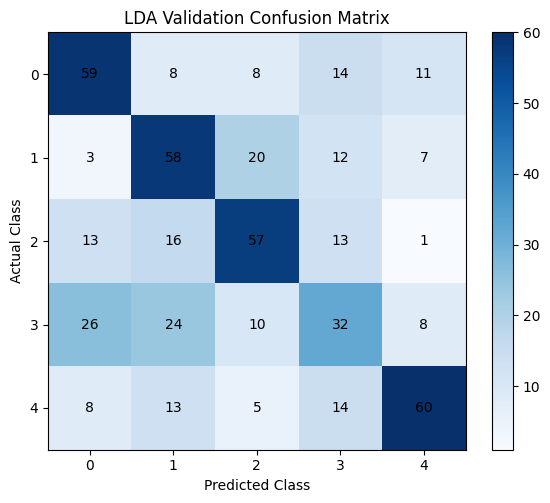

In [11]:

plt.figure(figsize=(6, 5))

plt.imshow(lda_cm, cmap="Blues")

plt.title("LDA Validation Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.xticks(range(5))
plt.yticks(range(5))

plt.colorbar()

for i in range(5):
    for j in range(5):
        plt.text(
            j, i, lda_cm[i, j],
            ha="center",
            va="center",
            color="black"
        )

plt.tight_layout()
plt.show()


In [12]:

class KNNClassifier:

    def __init__(self, k=5):
        self.k = k

    def fit(self, X, y):
        self.X_train = X
        self.y_train = y

    def predict(self, X):

        predictions = []

        for sample in X:

            # Calculate Euclidean distances
            difference = self.X_train - sample

            distances = np.sqrt(
                np.sum(difference ** 2, axis=1)
            )

            # Find K nearest neighbors
            nearest_indices = np.argsort(distances)[:self.k]

            # Get labels of nearest neighbors
            nearest_labels = self.y_train[nearest_indices]

            # Count votes for each class
            classes, counts = np.unique(
                nearest_labels, return_counts=True
            )

            # Choose class with highest votes
            predicted_class = classes[np.argmax(counts)]

            predictions.append(predicted_class)

        return np.array(predictions)


In [13]:

# Create KNN object
knn = KNNClassifier(k=5)

# Store training data
knn.fit(X_train, y_train)

# Predict validation labels
knn_val_predictions = knn.predict(X_val)

# Evaluate predictions
knn_evaluator = ModelEvaluator(
    y_val, knn_val_predictions
)

knn_accuracy = knn_evaluator.accuracy()
knn_cm = knn_evaluator.confusion_matrix()

print("KNN Validation Accuracy:", round(knn_accuracy, 2), "%")

print("\nKNN Confusion Matrix:")
print(knn_cm)

print("KNN Validation Accuracy:", round(knn_accuracy, 2), "%")


KNN Validation Accuracy: 47.0 %

KNN Confusion Matrix:
[[59 13 13 12  3]
 [ 7 63 16 10  4]
 [15 28 44 10  3]
 [28 25 12 27  8]
 [11 24 11 12 42]]
KNN Validation Accuracy: 47.0 %


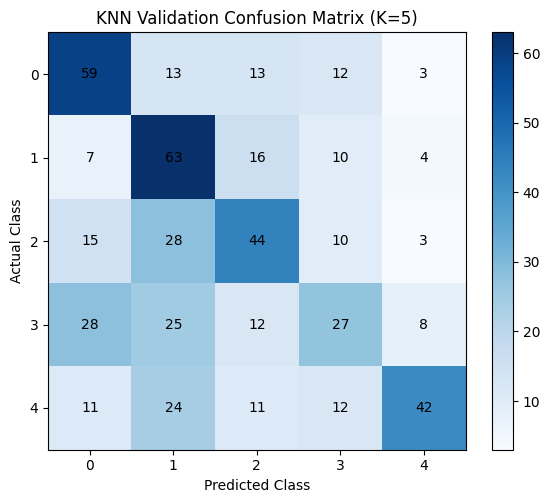

In [14]:

plt.figure(figsize=(6, 5))

plt.imshow(knn_cm, cmap="Blues")

plt.title("KNN Validation Confusion Matrix (K=5)")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.xticks(range(5))
plt.yticks(range(5))

plt.colorbar()

for i in range(5):
    for j in range(5):
        plt.text(
            j, i, knn_cm[i, j],
            ha="center",
            va="center",
            color="black"
        )

plt.tight_layout()
plt.show()


In [15]:

class GaussianMixture:

    def __init__(self, n_mixtures=2, max_iter=50):
        self.n_mixtures = n_mixtures
        self.max_iter = max_iter
        self.means = None
        self.variances = None
        self.weights = None

    def initialize(self, X):

        n_samples, n_features = X.shape

        # Select initial means deterministically
        indices = np.linspace(
            0, n_samples - 1,
            self.n_mixtures, dtype=int
        )

        self.means = X[indices].copy()

        # Initial variance for every component
        mean = np.sum(X, axis=0) / n_samples
        variance = np.sum(
            (X - mean) ** 2, axis=0
        ) / n_samples

        self.variances = np.tile(
            np.maximum(variance, 1e-6),
            (self.n_mixtures, 1)
        )

        # Equal initial mixture weights
        self.weights = np.ones(
            self.n_mixtures
        ) / self.n_mixtures

    def log_gaussian(self, X, component):

        mean = self.means[component]
        variance = self.variances[component]

        difference = X - mean

        log_probability = -0.5 * np.sum(
            np.log(2 * np.pi * variance)
            + (difference ** 2) / variance,
            axis=1
        )

        return log_probability


In [16]:

# Create GMM object
gmm_example = GaussianMixture(n_mixtures=2)

# Select training images belonging to Class 0
X_class0 = X_train[y_train == 0]

# Initialize Gaussian parameters
gmm_example.initialize(X_class0)

print("Class 0 training samples:", X_class0.shape)

print("Means shape:", gmm_example.means.shape)

print("Variances shape:", gmm_example.variances.shape)

print("Initial mixture weights:", gmm_example.weights)

print("log-density values:")
print(gmm_example.log_gaussian(X_class0[:5], 0))


Class 0 training samples: (400, 36)
Means shape: (2, 36)
Variances shape: (2, 36)
Initial mixture weights: [0.5 0.5]
log-density values:
[-31.12549592 -77.76761947 -60.25080504 -54.44649607 -60.36190384]


In [ ]:

# GMM Using KKT-Based Constrained Optimization
# No EM parameter updates
# Diagonal covariance matrices
# KKT-based simplex projection for mixture weights

class GaussianMixture:

    def __init__(self, n_mixtures=2, max_iter=50):
        self.n_mixtures = n_mixtures
        self.max_iter = max_iter

        self.means = None
        self.variances = None
        self.weights = None
        self.log_likelihood_history = []

    # ------------------------------------
    # Initialize GMM parameters
    # ------------------------------------
    def initialize(self, X):

        X = np.asarray(X, dtype=float)

        n_samples, n_features = X.shape

        if self.n_mixtures > n_samples:
            raise ValueError(
                "Number of mixtures exceeds number of samples"
            )

        indices = np.linspace(
            0, n_samples - 1,
            self.n_mixtures,
            dtype=int
        )

        self.means = X[indices].copy()

        variance = np.mean(
            (X - np.mean(X, axis=0)) ** 2,
            axis=0
        )

        self.variances = np.tile(
            np.maximum(variance, 1e-4),
            (self.n_mixtures, 1)
        )

        self.weights = (
            np.ones(self.n_mixtures)
            / self.n_mixtures
        )

    # ------------------------------------
    # Gaussian log probability
    # ------------------------------------
    def log_gaussian(self, X, component):

        mean = self.means[component]
        variance = np.maximum(
            self.variances[component],
            1e-4
        )

        difference = X - mean

        return -0.5 * np.sum(
            np.log(2 * np.pi * variance)
            + (difference ** 2) / variance,
            axis=1
        )

    # ------------------------------------
    # Numerically stable log-sum-exp
    # ------------------------------------
    def log_sum_exp(self, values):

        maximum = np.max(
            values,
            axis=1,
            keepdims=True
        )

        return maximum + np.log(
            np.sum(
                np.exp(values - maximum),
                axis=1,
                keepdims=True
            )
        )

    # ------------------------------------
    # KKT-based projection of weights
    # Constraints:
    # sum(weights) = 1
    # weights >= 0
    # ------------------------------------
    def project_weights(self, values):

        sorted_values = np.sort(values)[::-1]

        cumulative = np.cumsum(sorted_values)

        indices = np.arange(
            1,
            len(values) + 1
        )

        condition = (
            sorted_values
            - (cumulative - 1) / indices
        ) > 0

        rho = np.where(condition)[0][-1]

        threshold = (
            cumulative[rho] - 1
        ) / (rho + 1)

        projected = np.maximum(
            values - threshold,
            0
        )

        return projected

    # ------------------------------------
    # Calculate log-likelihood
    # ------------------------------------
    def score_samples(self, X):

        X = np.asarray(X, dtype=float)

        log_probabilities = np.column_stack([
            self.log_gaussian(X, k)
            + np.log(
                max(self.weights[k], 1e-12)
            )
            for k in range(self.n_mixtures)
        ])

        return self.log_sum_exp(
            log_probabilities
        ).ravel()

    # ------------------------------------
    # KKT-based projected gradient training
    # ------------------------------------
    def fit(self, X):

        X = np.asarray(X, dtype=float)

        self.initialize(X)

        self.log_likelihood_history = []

        previous_likelihood = np.sum(
            self.score_samples(X)
        )

        self.log_likelihood_history.append(
            previous_likelihood
        )

        tolerance = 1e-4

        for iteration in range(self.max_iter):

            # Component log probabilities
            log_probabilities = np.column_stack([
                self.log_gaussian(X, k)
                + np.log(
                    max(self.weights[k], 1e-12)
                )
                for k in range(self.n_mixtures)
            ])

            log_total = self.log_sum_exp(
                log_probabilities
            )

            # Posterior probabilities are used
            # to calculate gradients, not EM updates
            probabilities = np.exp(
                log_probabilities - log_total
            )

            mean_gradient = np.zeros_like(
                self.means
            )

            log_variance_gradient = np.zeros_like(
                self.variances
            )

            # Gradients for means and log variances
            for k in range(self.n_mixtures):

                difference = X - self.means[k]

                responsibility = (
                    probabilities[:, k, None]
                )

                mean_gradient[k] = np.mean(
                    responsibility
                    * difference
                    / self.variances[k],
                    axis=0
                )

                log_variance_gradient[k] = (
                    0.5 * np.mean(
                        responsibility * (
                            difference ** 2
                            / self.variances[k]
                            - 1
                        ),
                        axis=0
                    )
                )

            # Gradient for mixture weights
            weight_gradient = np.mean(
                probabilities
                / np.maximum(
                    self.weights,
                    1e-12
                ),
                axis=0
            )

            # Save current parameters
            old_means = self.means.copy()
            old_variances = self.variances.copy()
            old_weights = self.weights.copy()

            step_size = 0.1
            improved = False

            # Backtracking line search
            for attempt in range(25):

                new_means = (
                    old_means
                    + step_size * mean_gradient
                )

                new_variances = np.maximum(
                    old_variances * np.exp(
                        np.clip(
                            step_size
                            * log_variance_gradient,
                            -2,
                            2
                        )
                    ),
                    1e-4
                )

                # Apply KKT-derived projection
                new_weights = self.project_weights(
                    old_weights
                    + step_size * weight_gradient
                )

                # Evaluate candidate parameters
                self.means = new_means
                self.variances = new_variances
                self.weights = new_weights

                new_likelihood = np.sum(
                    self.score_samples(X)
                )

                if (
                    np.isfinite(new_likelihood)
                    and new_likelihood
                    >= previous_likelihood - 1e-9
                ):
                    improved = True
                    break

                step_size *= 0.5

            if not improved:

                self.means = old_means
                self.variances = old_variances
                self.weights = old_weights

                break

            improvement = (
                new_likelihood
                - previous_likelihood
            )

            previous_likelihood = new_likelihood

            self.log_likelihood_history.append(
                new_likelihood
            )

            if improvement < tolerance:
                break

        return self



In [43]:

# GMM Training Using KKT-Based Optimization

gmm_example = GaussianMixture(
    n_mixtures=2,
    max_iter=50
)

# Select Class 0 training images
X_class0 = X_train[y_train == 0]

# Train GMM using KKT-based optimization
gmm_example.fit(X_class0)

print("GMM Training Completed!")
print("----------------------------------")

print("Number of mixtures:", gmm_example.n_mixtures)

print("\nLearned mixture weights:")
print(gmm_example.weights)

print("\nSum of mixture weights:")
print(np.sum(gmm_example.weights))

print("\nMeans shape:")
print(gmm_example.means.shape)

print("\nVariances shape:")
print(gmm_example.variances.shape)

print("\nNumber of iterations:")
print(len(gmm_example.log_likelihood_history) - 1)

print("\nFinal log-likelihood:")
print(gmm_example.log_likelihood_history[-1])


GMM Training Completed!
----------------------------------
Number of mixtures: 2

Learned mixture weights:
[0.6288625 0.3711375]

Sum of mixture weights:
1.0

Means shape:
(2, 36)

Variances shape:
(2, 36)

Number of iterations:
50

Final log-likelihood:
-18729.21538482039


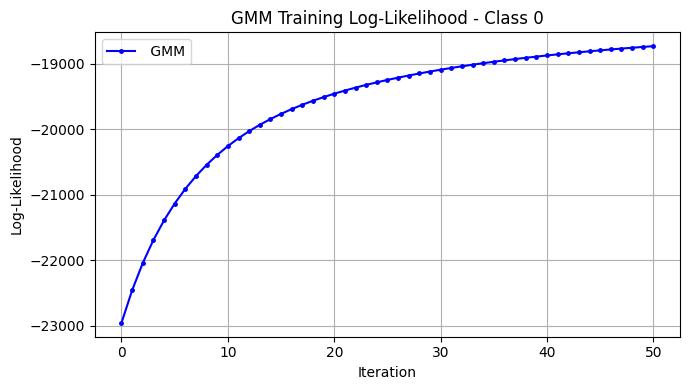

In [45]:

# GMM KKT-Based Training Log-Likelihood Graph

plt.figure(figsize=(7, 4))

plt.plot(
    gmm_example.log_likelihood_history,
    marker=".",
    markersize=5,
    color="blue",
    label=" GMM"
)

plt.title("GMM Training Log-Likelihood - Class 0")
plt.xlabel("Iteration")
plt.ylabel("Log-Likelihood")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [20]:

class GMMClassifier:

    def __init__(self, n_mixtures=2, max_iter=50):
        self.n_mixtures = n_mixtures
        self.max_iter = max_iter
        self.models = {}
        self.priors = {}

    def fit(self, X, y):

        self.classes = np.unique(y)

        for cls in self.classes:

            # Select training samples of this class
            X_class = X[y == cls]

            # Create a Gaussian mixture model
            model = GaussianMixture(
                n_mixtures=self.n_mixtures,
                max_iter=self.max_iter
            )

            # Train the model
            model.fit(X_class)

            # Store the trained model
            self.models[cls] = model

            # Calculate class prior probability
            self.priors[cls] = len(X_class) / len(X)

        return self

    def predict(self, X):

        scores = []

        for cls in self.classes:

            # Log-density plus class prior
            class_score = (
                self.models[cls].score_samples(X)
                + np.log(self.priors[cls])
            )

            scores.append(class_score)

        scores = np.column_stack(scores)

        predicted_indices = np.argmax(scores, axis=1)

        return self.classes[predicted_indices]


In [47]:

# GMM Classification Using KKT-Based Optimization

gmm_classifier = GMMClassifier(
    n_mixtures=2,
    max_iter=50
)

# Train GMM on all five classes
gmm_classifier.fit(X_train, y_train)

# Predict validation data
gmm_val_predictions = gmm_classifier.predict(X_val)

# Calculate accuracy and confusion matrix
gmm_evaluator = ModelEvaluator(
    y_val,
    gmm_val_predictions
)

gmm_accuracy = gmm_evaluator.accuracy()
gmm_cm = gmm_evaluator.confusion_matrix()

print("GMM Classification Completed!")
print("----------------------------------------")

print(
    "GMM Validation Accuracy:",
    round(gmm_accuracy, 2), "%"
)

print("\nGMM Confusion Matrix:")
print(gmm_cm)


GMM Classification Completed!
----------------------------------------
GMM Validation Accuracy: 50.6 %

GMM Confusion Matrix:
[[61 10 12 10  7]
 [ 4 62 17 12  5]
 [10 27 56  6  1]
 [34 23 12 25  6]
 [15 18  3 15 49]]


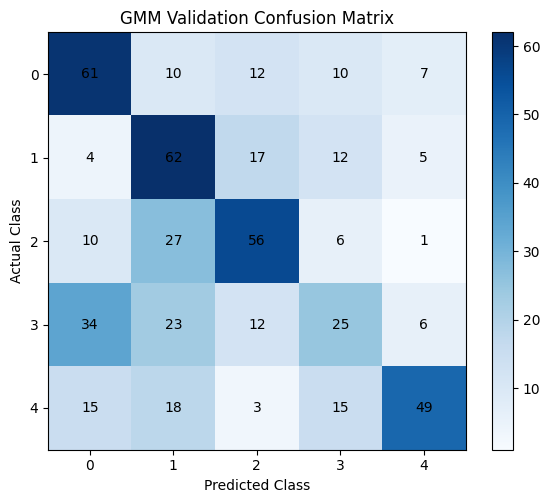

In [49]:

# GMM KKT-Based Validation Confusion Matrix

plt.figure(figsize=(6, 5))

plt.imshow(gmm_cm, cmap="Blues")

plt.title("GMM Validation Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

classes = np.unique(y_val)

plt.xticks(range(len(classes)), classes)
plt.yticks(range(len(classes)), classes)

plt.colorbar()

for i in range(len(classes)):
    for j in range(len(classes)):
        plt.text(
            j, i, gmm_cm[i, j],
            ha="center",
            va="center",
            color="black"
        )

plt.tight_layout()
plt.show()


In [23]:

class SVMClassifier:

    def __init__(self, learning_rate=0.001,
                 lambda_param=0.01, n_iters=1000):

        self.learning_rate = learning_rate
        self.lambda_param = lambda_param
        self.n_iters = n_iters

        self.weights = None
        self.biases = None
        self.classes = None

    def fit(self, X, y):

        n_samples, n_features = X.shape

        self.classes = np.unique(y)
        n_classes = len(self.classes)

        self.weights = np.zeros((n_classes, n_features))
        self.biases = np.zeros(n_classes)

        for i, cls in enumerate(self.classes):

            # Current class = +1, other classes = -1
            y_binary = np.where(y == cls, 1, -1)

            w = np.zeros(n_features)
            b = 0.0

            for iteration in range(self.n_iters):

                margins = y_binary * (X @ w + b)

                # Samples violating the SVM margin
                mask = margins < 1

                # Gradient of regularized hinge loss
                dw = (
                    2 * self.lambda_param * w
                    - (X[mask].T @ y_binary[mask]) / n_samples
                )

                db = -np.sum(y_binary[mask]) / n_samples

                # Update parameters
                w = w - self.learning_rate * dw
                b = b - self.learning_rate * db

            self.weights[i] = w
            self.biases[i] = b

        return self

    def predict(self, X):

        scores = X @ self.weights.T + self.biases

        predicted_indices = np.argmax(scores, axis=1)

        return self.classes[predicted_indices]


In [24]:

# Create SVM object
svm_classifier = SVMClassifier(
    learning_rate=0.001,
    lambda_param=0.01,
    n_iters=1000
)

# Train the classifier
svm_classifier.fit(X_train, y_train)

# Predict validation labels
svm_val_predictions = svm_classifier.predict(X_val)

# Evaluate
svm_evaluator = ModelEvaluator(
    y_val, svm_val_predictions
)

svm_accuracy = svm_evaluator.accuracy()
svm_cm = svm_evaluator.confusion_matrix()

print("SVM training completed!")

print("SVM Validation Accuracy:",
      round(svm_accuracy, 2), "%")

print("\nSVM Confusion Matrix:")
print(svm_cm)


SVM training completed!
SVM Validation Accuracy: 48.2 %

SVM Confusion Matrix:
[[67 13  5  5 10]
 [ 9 61 10  4 16]
 [22 25 31 17  5]
 [37 25  4 17 17]
 [10 13  3  9 65]]


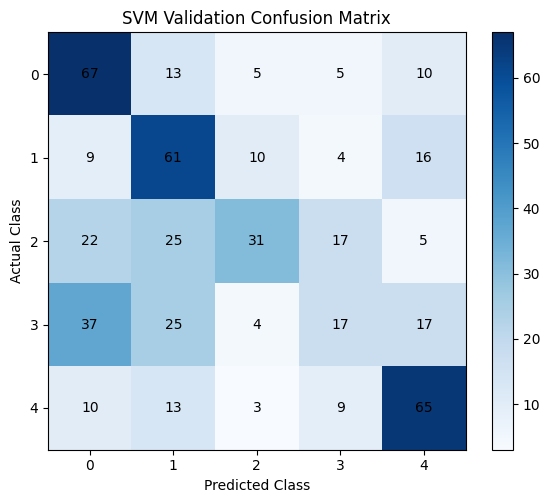

In [25]:

# Plot SVM Confusion Matrix

plt.figure(figsize=(6, 5))

plt.imshow(svm_cm, cmap="Blues")

plt.title("SVM Validation Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.xticks(range(5))
plt.yticks(range(5))

plt.colorbar()

for i in range(5):
    for j in range(5):
        plt.text(
            j, i, svm_cm[i, j],
            ha="center",
            va="center",
            color="black"
        )

plt.tight_layout()
plt.show()


In [26]:

print("IMAGE FEATURES - VALIDATION RESULTS")


print("LDA Accuracy:", round(lda_accuracy, 2), "%")
print("KNN Accuracy:", round(knn_accuracy, 2), "%")
print("GMM Accuracy:", round(gmm_accuracy, 2), "%")
print("SVM Accuracy:", round(svm_accuracy, 2), "%")


IMAGE FEATURES - VALIDATION RESULTS
LDA Accuracy: 53.2 %
KNN Accuracy: 47.0 %
GMM Accuracy: 50.6 %
SVM Accuracy: 48.2 %


In [27]:

class PCA:

    def __init__(self, variance_threshold=0.95):
        self.variance_threshold = variance_threshold
        self.mean = None
        self.components = None
        self.n_components = None
        self.explained_variance_ratio = None

    def fit(self, X):

        n_samples, n_features = X.shape

        # Step 1: Calculate feature means
        self.mean = np.sum(X, axis=0) / n_samples

        # Step 2: Center the training data
        X_centered = X - self.mean

        # Step 3: Calculate covariance matrix
        covariance = (
            X_centered.T @ X_centered
        ) / (n_samples - 1)

        # Step 4: Calculate eigenvalues and eigenvectors
        eigenvalues, eigenvectors = np.linalg.eigh(
            covariance
        )

        # Step 5: Arrange in descending order
        indices = np.argsort(eigenvalues)[::-1]

        eigenvalues = eigenvalues[indices]
        eigenvectors = eigenvectors[:, indices]

        # Avoid tiny negative values from numerical errors
        eigenvalues = np.maximum(eigenvalues, 0)

        # Step 6: Calculate explained variance ratio
        total_variance = np.sum(eigenvalues)

        if total_variance <= 0:
            raise ValueError("PCA requires nonzero variance")

        self.explained_variance_ratio = (
            eigenvalues / total_variance
        )

        cumulative_variance = np.cumsum(
            self.explained_variance_ratio
        )

        # Step 7: Select components retaining 95% variance
        self.n_components = (
            np.searchsorted(
                cumulative_variance,
                self.variance_threshold
            ) + 1
        )

        self.components = eigenvectors[
            :, :self.n_components
        ]

        return self

    def transform(self, X):

        if self.components is None:
            raise ValueError("Fit PCA before transform")

        X_centered = X - self.mean

        return X_centered @ self.components


In [28]:

# Create PCA object
pca = PCA(variance_threshold=0.95)

# Learn PCA using training data only
pca.fit(X_train)

# Transform all three datasets
X_train_pca = pca.transform(X_train)
X_val_pca = pca.transform(X_val)
X_test_pca = pca.transform(X_test)

print("PCA completed successfully!")

print("\nOriginal number of features:",
      X_train.shape[1])

print("Reduced number of features:",
      pca.n_components)

print("\nTraining shape:", X_train_pca.shape)
print("Validation shape:", X_val_pca.shape)
print("Testing shape:", X_test_pca.shape)

print("\nTotal retained variance:",
      round(
          np.sum(
              pca.explained_variance_ratio[
                  :pca.n_components
              ]
          ) * 100, 2
      ), "%")


PCA completed successfully!

Original number of features: 36
Reduced number of features: 30

Training shape: (2000, 30)
Validation shape: (500, 30)
Testing shape: (500, 30)

Total retained variance: 95.78 %


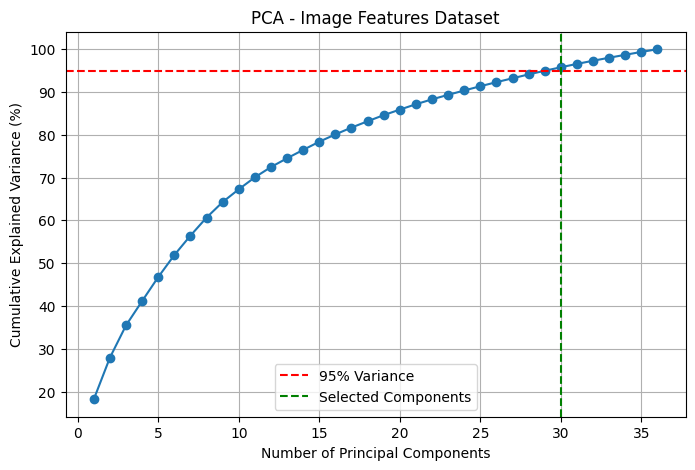

In [29]:

cumulative_variance = np.cumsum(
    pca.explained_variance_ratio
) * 100

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker="o"
)

plt.axhline(
    y=95,
    color="red",
    linestyle="--",
    label="95% Variance"
)

plt.axvline(
    x=pca.n_components,
    color="green",
    linestyle="--",
    label="Selected Components"
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance (%)")
plt.title("PCA - Image Features Dataset")

plt.legend()
plt.grid(True)
plt.show()


In [30]:

# Create a new LDA classifier
lda_pca = LDAClassifier()

# Train using PCA-reduced features
lda_pca.fit(X_train_pca, y_train)

# Predict validation labels
lda_pca_predictions = lda_pca.predict(X_val_pca)

# Evaluate accuracy
lda_pca_evaluator = ModelEvaluator(
    y_val, lda_pca_predictions
)

lda_pca_accuracy = lda_pca_evaluator.accuracy()
lda_pca_cm = lda_pca_evaluator.confusion_matrix()

print("LDA After PCA - Completed!")

print("\nOriginal Features:", X_train.shape[1])
print("PCA Features:", X_train_pca.shape[1])

print("\nLDA Before PCA:", round(lda_accuracy, 2), "%")
print("LDA After PCA:", round(lda_pca_accuracy, 2), "%")

print("\nConfusion Matrix:")
print(lda_pca_cm)


LDA After PCA - Completed!

Original Features: 36
PCA Features: 30

LDA Before PCA: 53.2 %
LDA After PCA: 53.2 %

Confusion Matrix:
[[55 12  7 15 11]
 [ 4 61 19  8  8]
 [13 17 54 15  1]
 [26 22  8 36  8]
 [10 13  5 12 60]]


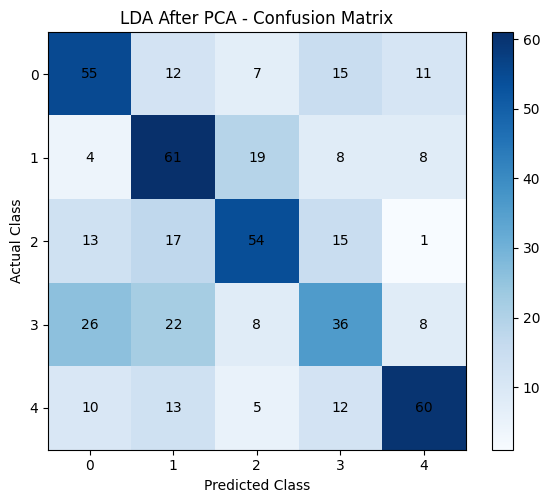

In [31]:

plt.figure(figsize=(6, 5))

plt.imshow(lda_pca_cm, cmap="Blues")

plt.title("LDA After PCA - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.xticks(range(5))
plt.yticks(range(5))

plt.colorbar()

for i in range(5):
    for j in range(5):
        plt.text(
            j, i, lda_pca_cm[i, j],
            ha="center",
            va="center",
            color="black"
        )

plt.tight_layout()
plt.show()


In [32]:

# Create KNN classifier
knn_pca = KNNClassifier(k=5)

# Train using PCA features
knn_pca.fit(X_train_pca, y_train)

# Predict validation labels
knn_pca_predictions = knn_pca.predict(X_val_pca)

# Evaluate
knn_pca_evaluator = ModelEvaluator(
    y_val, knn_pca_predictions
)

knn_pca_accuracy = knn_pca_evaluator.accuracy()
knn_pca_cm = knn_pca_evaluator.confusion_matrix()

print("KNN After PCA - Completed!")

print("\nOriginal Features:", X_train.shape[1])
print("PCA Features:", X_train_pca.shape[1])

print("\nKNN Before PCA:", round(knn_accuracy, 2), "%")
print("KNN After PCA:", round(knn_pca_accuracy, 2), "%")

print("\nConfusion Matrix:")
print(knn_pca_cm)


KNN After PCA - Completed!

Original Features: 36
PCA Features: 30

KNN Before PCA: 47.0 %
KNN After PCA: 46.8 %

Confusion Matrix:
[[64 16  9  9  2]
 [ 4 61 21  8  6]
 [16 26 45 11  2]
 [33 21 14 22 10]
 [15 21  9 13 42]]


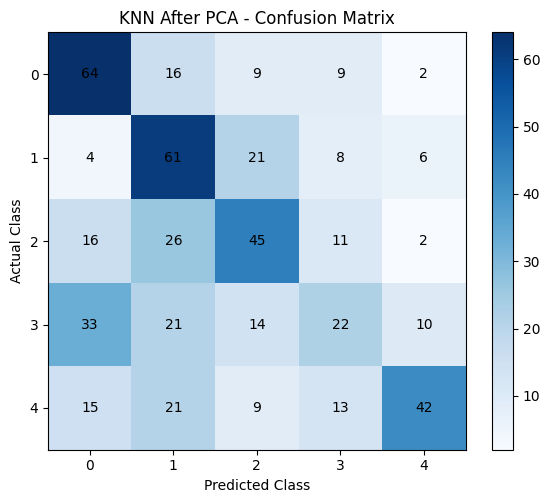

In [33]:

plt.figure(figsize=(6, 5))

plt.imshow(knn_pca_cm, cmap="Blues")

plt.title("KNN After PCA - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.xticks(range(5))
plt.yticks(range(5))

plt.colorbar()

for i in range(5):
    for j in range(5):
        plt.text(
            j, i, knn_pca_cm[i, j],
            ha="center",
            va="center",
            color="black"
        )

plt.tight_layout()
plt.show()


In [51]:

# GMM Classification After PCA - KKT-Based Optimization

gmm_pca = GMMClassifier(
    n_mixtures=2,
    max_iter=50
)

# Train GMM using PCA features
gmm_pca.fit(X_train_pca, y_train)

# Predict validation data
gmm_pca_predictions = gmm_pca.predict(X_val_pca)

# Evaluate the model
gmm_pca_evaluator = ModelEvaluator(
    y_val,
    gmm_pca_predictions
)

gmm_pca_accuracy = gmm_pca_evaluator.accuracy()
gmm_pca_cm = gmm_pca_evaluator.confusion_matrix()

print("GMM After PCA - Completed!")
print("-------------------------------------")

print("\nOriginal Features:", X_train.shape[1])
print("PCA Features:", X_train_pca.shape[1])

print("\nGMM Before PCA:", round(gmm_accuracy, 2), "%")
print("GMM After PCA:", round(gmm_pca_accuracy, 2), "%")

print("\nGMM After PCA Confusion Matrix:")
print(gmm_pca_cm)


GMM After PCA - Completed!
-------------------------------------

Original Features: 36
PCA Features: 30

GMM Before PCA: 50.6 %
GMM After PCA: 46.0 %

GMM After PCA Confusion Matrix:
[[49 24 10  5 12]
 [ 0 42 42  7  9]
 [ 9 22 64  1  4]
 [24 36 15 17  8]
 [ 3 16 13 10 58]]


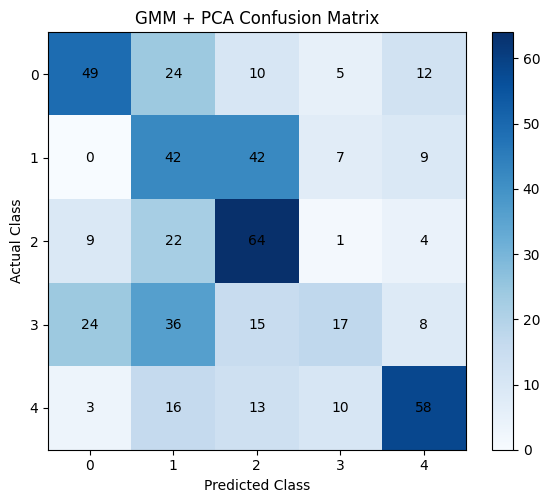

In [53]:

# GMM + PCA - KKT-Based Confusion Matrix

plt.figure(figsize=(6, 5))

plt.imshow(gmm_pca_cm, cmap="Blues")

plt.title("GMM + PCA Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

classes = np.unique(y_val)

plt.xticks(range(len(classes)), classes)
plt.yticks(range(len(classes)), classes)

plt.colorbar()

for i in range(len(classes)):
    for j in range(len(classes)):
        plt.text(
            j, i, gmm_pca_cm[i, j],
            ha="center",
            va="center",
            color="black"
        )

plt.tight_layout()
plt.show()


In [36]:

# Create SVM classifier
svm_pca = SVMClassifier(
    learning_rate=0.001,
    lambda_param=0.01,
    n_iters=1000
)

# Train using PCA-reduced features
svm_pca.fit(X_train_pca, y_train)

# Predict validation labels
svm_pca_predictions = svm_pca.predict(X_val_pca)

# Evaluate predictions
svm_pca_evaluator = ModelEvaluator(
    y_val, svm_pca_predictions
)

svm_pca_accuracy = svm_pca_evaluator.accuracy()
svm_pca_cm = svm_pca_evaluator.confusion_matrix()

print("SVM After PCA - Completed!")

print("\nOriginal Features:", X_train.shape[1])
print("PCA Features:", X_train_pca.shape[1])

print("\nSVM Before PCA:", round(svm_accuracy, 2), "%")
print("SVM After PCA:", round(svm_pca_accuracy, 2), "%")

print("\nConfusion Matrix:")
print(svm_pca_cm)


SVM After PCA - Completed!

Original Features: 36
PCA Features: 30

SVM Before PCA: 48.2 %
SVM After PCA: 47.0 %

Confusion Matrix:
[[66 14  5  5 10]
 [ 9 61  9  4 17]
 [22 29 27 17  5]
 [37 26  4 16 17]
 [11 14  3  7 65]]


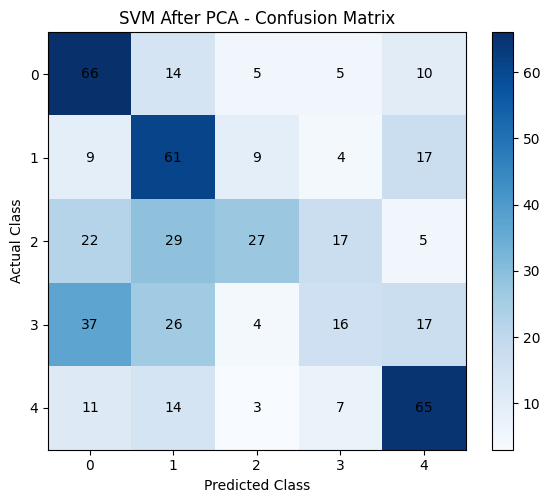

In [37]:

plt.figure(figsize=(6, 5))

plt.imshow(svm_pca_cm, cmap="Blues")

plt.title("SVM After PCA - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.xticks(range(5))
plt.yticks(range(5))

plt.colorbar()

for i in range(5):
    for j in range(5):
        plt.text(
            j, i, svm_pca_cm[i, j],
            ha="center",
            va="center",
            color="black"
        )

plt.tight_layout()
plt.show()


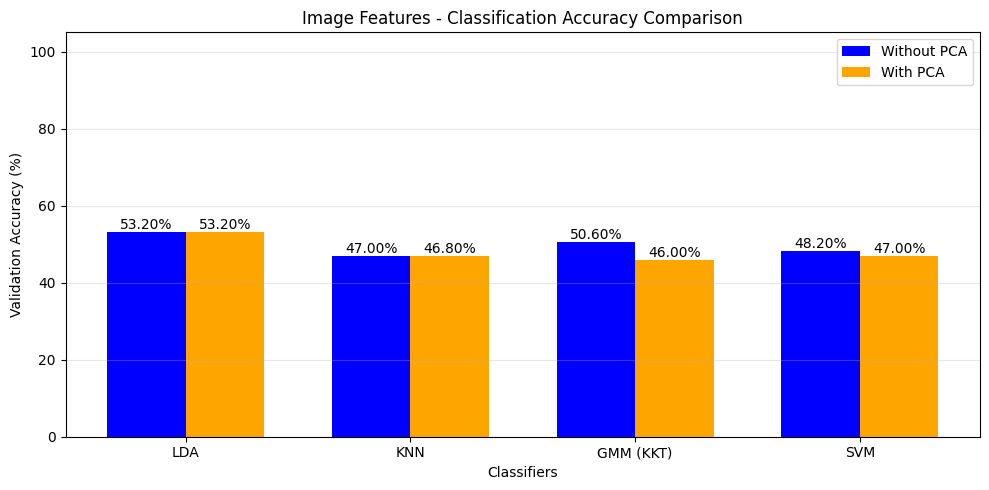

VALIDATION ACCURACY COMPARISON
--------------------------------
LDA | Without PCA: 53.2 % | With PCA: 53.2 %
KNN | Without PCA: 47.0 % | With PCA: 46.8 %
GMM (KKT) | Without PCA: 50.6 % | With PCA: 46.0 %
SVM | Without PCA: 48.2 % | With PCA: 47.0 %


In [54]:

# Final Validation Comparison - Before and After PCA
# GMM uses KKT-based optimization

classifiers = ["LDA", "KNN", "GMM (KKT)", "SVM"]

before_pca = [
    lda_accuracy,
    knn_accuracy,
    gmm_accuracy,
    svm_accuracy
]

after_pca = [
    lda_pca_accuracy,
    knn_pca_accuracy,
    gmm_pca_accuracy,
    svm_pca_accuracy
]

x = np.arange(len(classifiers))
width = 0.35

plt.figure(figsize=(10, 5))

bars1 = plt.bar(
    x - width / 2,
    before_pca,
    width,
    label="Without PCA",
    color="blue"
)

bars2 = plt.bar(
    x + width / 2,
    after_pca,
    width,
    label="With PCA",
    color="orange"
)

plt.xlabel("Classifiers")
plt.ylabel("Validation Accuracy (%)")
plt.title("Image Features - Classification Accuracy Comparison")

plt.xticks(x, classifiers)
plt.ylim(0, 105)

plt.bar_label(bars1, fmt="%.2f%%")
plt.bar_label(bars2, fmt="%.2f%%")

plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print("VALIDATION ACCURACY COMPARISON")
print("--------------------------------")

for i in range(len(classifiers)):
    print(
        classifiers[i],
        "| Without PCA:", round(before_pca[i], 2), "%",
        "| With PCA:", round(after_pca[i], 2), "%"
    )


In [39]:

# Validation Accuracy Comparison

print("IMAGE FEATURES - VALIDATION RESULTS")
print("-----------------------------------")

print("LDA Before PCA:", lda_accuracy, "%")
print("LDA After PCA:", lda_pca_accuracy, "%")

print("KNN Before PCA:", knn_accuracy, "%")
print("KNN After PCA:", knn_pca_accuracy, "%")

print("GMM Before PCA:", gmm_accuracy, "%")
print("GMM After PCA:", gmm_pca_accuracy, "%")

print("SVM Before PCA:", svm_accuracy, "%")
print("SVM After PCA:", svm_pca_accuracy, "%")


IMAGE FEATURES - VALIDATION RESULTS
-----------------------------------
LDA Before PCA: 53.2 %
LDA After PCA: 53.2 %
KNN Before PCA: 47.0 %
KNN After PCA: 46.800000000000004 %
GMM Before PCA: 50.6 %
GMM After PCA: 46.0 %
SVM Before PCA: 48.199999999999996 %
SVM After PCA: 47.0 %


In [40]:

# Final Test Evaluation - All Classifiers

test_models = {
    "LDA Original": (lda, X_test),
    "KNN Original": (knn, X_test),
    "GMM Original": (gmm_classifier, X_test),
    "SVM Original": (svm_classifier, X_test),

    "LDA PCA": (lda_pca, X_test_pca),
    "KNN PCA": (knn_pca, X_test_pca),
    "GMM PCA": (gmm_pca, X_test_pca),
    "SVM PCA": (svm_pca, X_test_pca)
}

test_results = {}
test_predictions = {}

print("FINAL TEST RESULTS - IMAGE FEATURES")
print("-" * 50)

for name, (model, features) in test_models.items():

    predictions = model.predict(features)

    evaluator = ModelEvaluator(y_test, predictions)

    accuracy = evaluator.accuracy()

    test_results[name] = accuracy
    test_predictions[name] = predictions

    print(f"{name:<20}: {accuracy:.2f}%")


FINAL TEST RESULTS - IMAGE FEATURES
--------------------------------------------------
LDA Original        : 53.20%
KNN Original        : 45.00%
GMM Original        : 52.40%
SVM Original        : 49.40%
LDA PCA             : 53.20%
KNN PCA             : 41.60%
GMM PCA             : 44.40%
SVM PCA             : 49.00%
